# 03 - Tier 2: TF-IDF + Naive Bayes (classic ML)

**Pipeline:** NLTK preprocessing (`src/text_prep.py`) -> `TfidfVectorizer` -> `MultinomialNB`.

- **Tokenise:** NLTK `TweetTokenizer` lowercases, shortens stretched words ("sooooo") and keeps emoji.
- **Negation scope:** NLTK `mark_negation` adds `_NEG` to words after a negation, up to the next clause punctuation, so "not good" becomes `not good_NEG`.
- **Stopwords:** NLTK English stopwords are removed, **except** negations (not, no, don't, ...).

Hyperparameters are tuned with 5-fold cross-validation on **train only**, scored by macro-F1. The test set is used exactly once, at the end.

In [1]:
import sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from src.data_utils import load_split, load_hard_cases, PROJECT_ROOT
from src.eval_utils import evaluate_model, hard_case_breakdown, METRICS_PATH
from src.text_prep import preprocess, preprocess_many

SEED = 42
MODEL_DIR = PROJECT_ROOT / 'models'
MODEL_DIR.mkdir(exist_ok=True)

## 1. Preprocess the training set
Two variants, with and without negation marking, so cross-validation can decide whether `mark_negation` helps.

In [2]:
train = load_split('train')
y_train = train['label'].to_numpy()

start = time.perf_counter()
X_train = {
    'negation': preprocess_many(train['text'], negation=True),
    'plain': preprocess_many(train['text'], negation=False),
}
print(f'Preprocessed {len(train):,} reviews x 2 variants in {time.perf_counter() - start:.0f}s')
print('\nExample (negation variant):\n', X_train['negation'][0][:300])

Preprocessed 39,662 reviews x 2 variants in 336s

Example (negation variant):
 saw film tv many years ago saw film got tape thought reasonably well done not best_NEG movies_NEG good_NEG enough_NEG movie enough talent inspire many people especially younger kids acting good danny glover leading cast plot line not believable_NEG script_NEG well_NEG written_NEG movie also interest


## 2. Tune with 5-fold cross-validation (train only)

In [3]:
pipeline = Pipeline([
    # Text is already tokenised: split on whitespace and keep case/emoji as-is
    ('tfidf', TfidfVectorizer(token_pattern=r'\S+', lowercase=False, sublinear_tf=True)),
    ('nb', MultinomialNB()),
])
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [2, 5],
    'nb__alpha': [0.1, 0.3, 1.0],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

searches, cv_tables = {}, []
for variant, X in X_train.items():
    start = time.perf_counter()
    gs = GridSearchCV(pipeline, param_grid, scoring='f1_macro', cv=cv, n_jobs=-1)
    gs.fit(X, y_train)
    searches[variant] = gs
    t = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
    cv_tables.append(t.assign(variant=variant))
    print(f'{variant:>9}: best CV macro-F1 {gs.best_score_:.4f} {gs.best_params_} '
          f'({time.perf_counter() - start:.0f}s)')

cv_results = pd.concat(cv_tables, ignore_index=True)
cv_results = pd.concat([cv_results.drop(columns='params'),
                        pd.json_normalize(cv_results['params'])], axis=1)
cv_results.sort_values('mean_test_score', ascending=False).head(10).round(4)

 negation: best CV macro-F1 0.8916 {'nb__alpha': 0.3, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)} (181s)


    plain: best CV macro-F1 0.8944 {'nb__alpha': 0.3, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)} (332s)


,mean_test_score,std_test_score,variant,nb__alpha,tfidf__min_df,tfidf__ngram_range
17,0.8944,0.0037,plain,0.3,2,"(1, 2)"
13,0.8933,0.0028,plain,0.1,2,"(1, 2)"
21,0.8925,0.0038,plain,1.0,2,"(1, 2)"
19,0.8923,0.0031,plain,0.3,5,"(1, 2)"
5,0.8916,0.0031,negation,0.3,2,"(1, 2)"
15,0.8915,0.0037,plain,0.1,5,"(1, 2)"
1,0.8910,0.0024,negation,0.1,2,"(1, 2)"
23,0.8901,0.0042,plain,1.0,5,"(1, 2)"
9,0.8870,0.0032,negation,1.0,2,"(1, 2)"
3,0.8869,0.0031,negation,0.1,5,"(1, 2)"


In [4]:
best_variant = max(searches, key=lambda v: searches[v].best_score_)
best_search = searches[best_variant]
model = best_search.best_estimator_   # refit on all of train by GridSearchCV
USE_NEGATION = best_variant == 'negation'
print('Chosen variant:', best_variant)
print('Chosen params :', best_search.best_params_)
print(f"Vocabulary   : {len(model.named_steps['tfidf'].vocabulary_):,} features")

Chosen variant: plain
Chosen params : {'nb__alpha': 0.3, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Vocabulary   : 537,230 features


## 3. What did the model learn?
Features with the largest difference in log-probability between the classes.

In [5]:
vocab = np.array(model.named_steps['tfidf'].get_feature_names_out())
nb = model.named_steps['nb']
neg_i, pos_i = list(nb.classes_).index('negative'), list(nb.classes_).index('positive')
log_ratio = nb.feature_log_prob_[pos_i] - nb.feature_log_prob_[neg_i]
order = np.argsort(log_ratio)
pd.DataFrame({
    'most negative': vocab[order[:20]],
    'most positive': vocab[order[::-1][:20]],
})

,most negative,most positive
0,worst movie,8/ 10
1,worst movies,7/10
2,2/10,cast excellent
3,2 10,! 10/10
4,3/10,8/
5,one worst,highly recommended
6,4/10,won't regret
7,worst film,9/10
8,3 10,ponyo
9,worst films,not missed


In [6]:
# How negation-marked features lean (only meaningful if the negation variant won)
probe = ['good', 'good_NEG', 'bad', 'bad_NEG', 'recommend', 'recommend_NEG', 'worth', 'worth_NEG']
idx = {w: i for i, w in enumerate(vocab)}
pd.DataFrame([{'feature': w, 'log P(pos)/P(neg)': round(log_ratio[idx[w]], 3)}
              for w in probe if w in idx])

,feature,log P(pos)/P(neg)
0,good,0.020
1,bad,-1.303
2,recommend,0.495
3,worth,0.137


## 4. Score on test300 and the hard cases
Timing covers the full path, preprocessing plus prediction, because that is what serving the model would cost.

model                                            NLTK + Naive Bayes
accuracy                                                     0.8867
macro_f1                                                     0.8867
hard_cases_acc                                                  0.7
sec_per_1k                                                 4.183167
cost_per_1k                                                     0.0
n_test                                                          300
n_hard                                                           30
evaluated_at                              2026-11-19T10:24:54+00:00
notes             plain prep; ngram=(1, 2), min_df=2, alpha=0.3;...
dtype: object

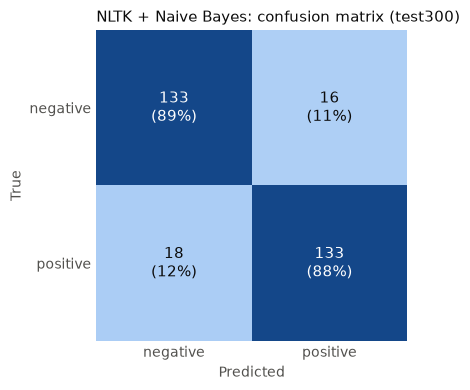

In [7]:
def predict_nb(texts):
    return list(model.predict(preprocess_many(texts, negation=USE_NEGATION)))

p = best_search.best_params_
nb_result = evaluate_model(
    'NLTK + Naive Bayes', predict_nb,
    notes=(f"{best_variant} prep; ngram={p['tfidf__ngram_range']}, "
           f"min_df={p['tfidf__min_df']}, alpha={p['nb__alpha']}; "
           f"CV macro-F1={best_search.best_score_:.4f}"),
)
pd.Series({k: v for k, v in nb_result.items() if k != 'confusion_matrix'})

In [8]:
joblib.dump({'model': model, 'use_negation': USE_NEGATION}, MODEL_DIR / 'nb_tfidf.joblib')
print('Saved', MODEL_DIR / 'nb_tfidf.joblib')

Saved C:\Users\b7ind\Python Bootcamp\Milestone4\models\nb_tfidf.joblib


In [9]:
hard_case_breakdown('NLTK + Naive Bayes')

,accuracy,correct,n
category,,,
contrast,0.333333,1,3
comparison,0.500000,1,2
idiom,0.500000,1,2
double_negative,0.500000,1,2
rhetorical_question,0.500000,1,2
rating,0.500000,1,2
negation,0.666667,2,3
slang_emoji,0.666667,2,3
faint_praise,1.000000,3,3


In [10]:
# Hard cases Naive Bayes got wrong (the hand-written set, not test data)
hard = load_hard_cases()
hard['prepped'] = preprocess_many(hard['text'], negation=USE_NEGATION)
hard['p_positive'] = model.predict_proba(hard['prepped'])[:, pos_i].round(3)
hard['pred'] = model.predict(hard['prepped'])
with pd.option_context('display.max_colwidth', 70):
    display(hard.loc[hard['pred'] != hard['label'],
                     ['id', 'category', 'label', 'p_positive', 'prepped']])

,id,category,label,p_positive,prepped
0,1,negation,positive,0.479,movie not bad happily watch
3,4,double_negative,positive,0.462,wasn't single scene didn't love
8,9,contrast,positive,0.098,acting wooden plot thin somehow loved every minute
10,11,contrast,positive,0.346,starts slow first half drags ending makes
17,18,comparison,positive,0.255,expected awful sequel actually even better original
22,23,idiom,positive,0.361,lead actress absolutely killed every scene
24,25,slang_emoji,positive,0.349,movie sick 🔥 🔥 no cap
27,28,rhetorical_question,positive,0.395,didn't anyone tell watch sooner ?
29,30,rating,positive,0.384,went expecting 3/10 walked thinking 9/10


## 5. Tier 1 vs Tier 2 so far

In [11]:
pd.read_csv(METRICS_PATH).set_index('model')[
    ['accuracy', 'macro_f1', 'hard_cases_acc', 'sec_per_1k', 'cost_per_1k']]

,accuracy,macro_f1,hard_cases_acc,sec_per_1k,cost_per_1k
model,,,,,
LLM zero-shot (Haiku 5.5),0.9567,0.9567,1.0000,1560.301000,0.075
Majority baseline,0.5033,0.3348,0.5000,0.000005,0.000
VADER,0.7267,0.7153,0.3333,4.675349,0.000
TextBlob,0.7100,0.6872,0.4000,2.104080,0.000
NLTK + Naive Bayes,0.8867,0.8867,0.7000,4.183167,0.000


### Notes

**Results on test300**

| Model | Accuracy | Macro-F1 | Hard-cases acc. | Sec / 1k | Cost / 1k |
|---|---|---|---|---|---|
| VADER | 0.727 | 0.715 | 0.33 | 4.7 | $0 |
| **NLTK + Naive Bayes** | **0.887** | **0.887** | **0.70** | 4.2 | ~$0 |

**Tuning (5-fold CV on train, scored by macro-F1)**
- Best setup: unigrams + bigrams, `min_df=2`, `alpha=0.3`, giving 537K features and CV macro-F1 0.894 (std 0.004).
- The CV estimate (0.894) and the test300 score (0.887) agree closely, so there is no sign of overfitting the tuning.
- Bigrams beat unigrams in every configuration; all of the top 10 use `(1, 2)`.
- **`mark_negation` did not help** (0.892 vs 0.894, within one standard deviation). Bigrams already capture short negations ("not bad", "don't waste"). The `_NEG` suffix also splits counts for words across their whole clause, which makes the features sparser. The plain variant was kept.

**Errors are balanced** on test300: 16 negative reviews predicted positive and 18 positive reviews predicted negative. VADER's positive bias is gone.

**What it learned**
- Ratings written inside reviews ("2/10", "8/10", "10/10") are among the strongest features in both directions.
- So are fixed phrases ("worst movie", "waste time", "highly recommended", "well worth").
- Some features are film-specific words ("ponyo", "felix"). The model is partly memorising titles that happened to be reviewed positively, which won't transfer to other domains.

**Hard cases: 21 of 30 (0.70), up from 0.33 for VADER**
- It got all 3 sarcasm, faint-praise and domain-polarity cases right, and both dark-plot cases.
- All 9 errors are **positive sentences predicted negative**. Short sentences that contain one negative-leaning word ("bad", "wooden", "drags", "awful", "killed", "no", "didn't") fall below 0.5, because positive evidence needs more text to build up. Examples:
  - "not bad at all…": P(positive) 0.48
  - "acting was wooden… but somehow I loved every minute": 0.10
  - "absolutely killed it": 0.36
- Contrast is its weakest category (1 of 3). A bag of words can't tell which side of the "but" decides the verdict.

**Speed and cost.** 4.2 s per 1,000 reviews (final run; 3.6 s on the first run), nearly all of it NLTK tokenisation (prediction itself takes milliseconds). Training plus the full grid search took about 12–15 minutes on a laptop CPU. Cost is effectively $0. The saved model is 32 MB (`models/`, git-ignored).

**Takeaway.** About 40K labelled reviews and a 50-year-old algorithm close most of the gap: +17 points of macro-F1 over VADER at similar speed. What remains is context: contrast clauses, comparisons and slang.